Energy Data Science Assignement 8. Statistical modelling

Mihhail Korasteljov  266050IV  


## Setup — dataset and fixed evaluation protocol
Training: 2013-07-01 to 2014-04-30; validation: 2014-05-01 to 2014-06-23; test: 2014-06-24 to 2014-06-30.  
The test week has seven daily folds, each forecasting 24 hours. nRMSE (%) = 100 × RMSE / mean(training demand). Missing timestamps are restored to an hourly grid; any missing historical demand is filled using **past values only**.

In [8]:
# Import Python libraries used Practical 11.
# Set the random seed and load the same training dataset as in Task 7.

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
warnings.filterwarnings("ignore", category=UserWarning)
np.random.seed(42)

DATA_FILE = "266050_training.csv"  # put the supplied CSV beside this notebook
# Read the hourly electricity demand data.
raw = pd.read_csv(DATA_FILE)
raw["timestamp"] = pd.to_datetime(raw["timestamp"], utc=True)
raw = raw.set_index("timestamp").sort_index()
full_index = pd.date_range(raw.index.min(), raw.index.max(), freq="h", tz="UTC")
missing_times = full_index.difference(raw.index)
energy = raw.reindex(full_index)
energy.index.name = "timestamp"

# Demand is available historically; fill any missing hour from the last known demand.
energy["Demand"] = energy["Demand"].ffill()
y = energy["Demand"].astype(float)
TRAIN_END = pd.Timestamp("2014-04-30 23:00:00", tz="UTC")
VALID_END = pd.Timestamp("2014-06-23 23:00:00", tz="UTC")
TEST_START = pd.Timestamp("2014-06-24 00:00:00", tz="UTC")
train = y.loc[:TRAIN_END]
validation = y.loc[TRAIN_END + pd.Timedelta(hours=1):VALID_END]
test = y.loc[TEST_START:]
trainval = y.loc[:VALID_END]
TRAIN_MEAN = train.mean()
print("Missing hourly timestamps:", list(missing_times))
print("Training:", train.index.min(), "to", train.index.max(), len(train))
print("Validation:", validation.index.min(), "to", validation.index.max(), len(validation))
print("Test:", test.index.min(), "to", test.index.max(), len(test))
print("Fixed training mean:", round(TRAIN_MEAN, 5), "kW")
assert len(test) == 168

def metrics(actual, forecast):
    a, f = np.asarray(actual, float), np.asarray(forecast, float)
    assert len(a) == len(f) and np.isfinite(f).all()
    return {"MAE [kW]": np.mean(np.abs(a-f)),
            "nRMSE [%]": 100*np.sqrt(np.mean((a-f)**2))/TRAIN_MEAN}

Missing hourly timestamps: [Timestamp('2013-12-31 23:00:00+0000', tz='UTC')]
Training: 2013-07-01 00:00:00+00:00 to 2014-04-30 23:00:00+00:00 7296
Validation: 2014-05-01 00:00:00+00:00 to 2014-06-23 23:00:00+00:00 1296
Test: 2014-06-24 00:00:00+00:00 to 2014-06-30 23:00:00+00:00 168
Fixed training mean: 0.53907 kW


**8.1. Stationarise the data, if necessary. State which test(s) you used, the resulting statistics, and your differencing choice.**

C:\Users\mkora\AppData\Local\Temp\ipykernel_5112\3832277539.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  a = adfuller(s, autolag="AIC")
C:\Users\mkora\AppData\Local\Temp\ipykernel_5112\3832277539.py:8: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  k = kpss(s, regression="c", nlags="auto")
C:\Users\mkora\AppData\Local\Temp\ipyk

,Series,ADF statistic,ADF p,KPSS statistic,KPSS p
0,Original demand,-10.7152,0.0,2.3957,0.01
1,Seasonal difference (24h),-23.9506,0.0,0.0031,0.10
2,First difference (1h),-22.4716,0.0,0.0478,0.10


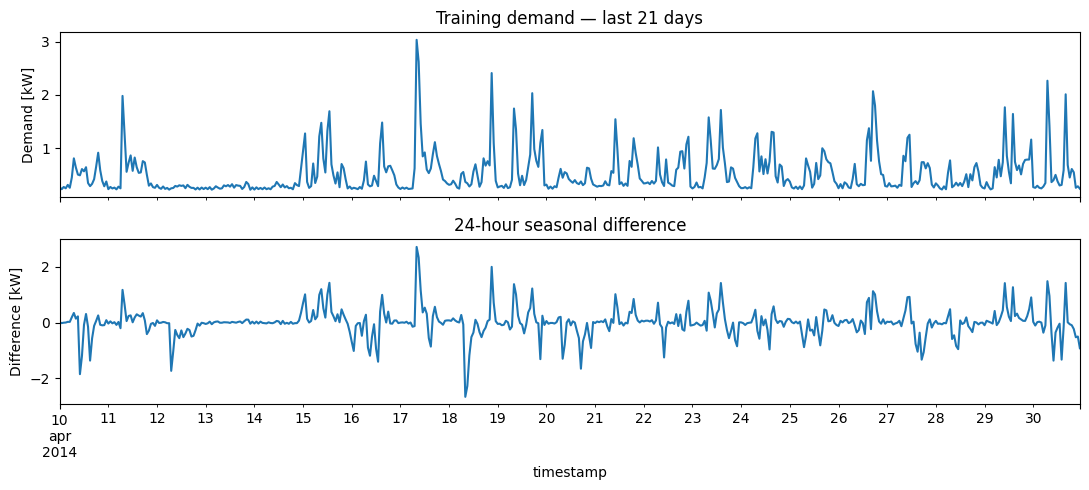

ADF original p: 0.0
ADF seasonal difference p: 0.0


In [9]:
# Task 8.1: Check if the demand series is stationary.
# ADF tests for a unit root; KPSS tests for stationarity.
# Compare original demand with 1-hour and 24-hour differences.

def stationarity_report(s, label):
    s = pd.Series(s).dropna()
    a = adfuller(s, autolag="AIC")
    k = kpss(s, regression="c", nlags="auto")
    return {"Series":label, "ADF statistic":a[0], "ADF p":a[1],
            "KPSS statistic":k[0], "KPSS p":k[1]}

# Subtract the demand from the same hour yesterday.
seasonal_diff = train.diff(24).dropna()

# Subtract the demand from the previous hour.
first_diff = train.diff().dropna()

# Show the stationarity test statistics in one table.
stationarity = pd.DataFrame([
    stationarity_report(train, "Original demand"),
    stationarity_report(seasonal_diff, "Seasonal difference (24h)"),
    stationarity_report(first_diff, "First difference (1h)")])
display(stationarity.round(4))
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
train.iloc[-24*21:].plot(ax=axes[0], title="Training demand — last 21 days", ylabel="Demand [kW]")
seasonal_diff.iloc[-24*21:].plot(ax=axes[1], title="24-hour seasonal difference", ylabel="Difference [kW]")
plt.tight_layout(); plt.show()
print("ADF original p:", round(stationarity.iloc[0]["ADF p"], 5))
print("ADF seasonal difference p:", round(stationarity.iloc[1]["ADF p"], 5))

**Comment to 8.1:** The ADF test (p < 0.05) suggests that the original demand series is stationary. Therefore, I choose d = 0 (no ordinary differencing). I also examine the 24-hour seasonal difference to check daily patterns.

**8.2. Construct, analyse, and describe ACF and PACF plots. Read the model order from the plots explicitly: state which lags are significant, what cut-off or decay pattern you see, and which (p, q) that pattern implies.**



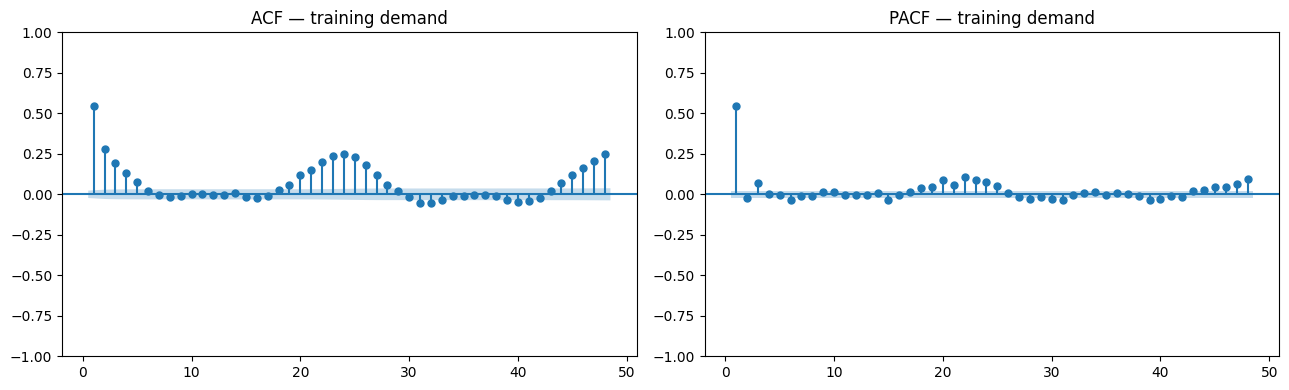

,lag,ACF,PACF
0,1,0.543,0.543
1,2,0.280,-0.021
2,3,0.193,0.070
3,24,0.246,0.073
4,48,0.249,0.096


Approximate 95% significance threshold: +/- 0.023


In [10]:
#ACF measures total correlation with previous observations; PACF removes the effects of intermediate lags. 
# ACF that decays and PACF dominated by lag 1 motivates an AR(1) candidate. 
#Strong lag-24 correlation suggests daily seasonality, which a small nonseasonal ARMA model may not fully capture.

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(train, lags=48, ax=axes[0], zero=False)
plot_pacf(train, lags=48, ax=axes[1], zero=False, method="ywm")
axes[0].set_title("ACF — training demand")
axes[1].set_title("PACF — training demand")
plt.tight_layout(); plt.show()
N=len(train); limit=1.96/np.sqrt(N)
acf_values=acf(train, nlags=48, fft=True)
pacf_values=pacf(train, nlags=48, method="ywm")

# Show selected lag values to support the chosen model order.
lag_table=pd.DataFrame({"lag": [1,2,3,24,48],
 "ACF": [acf_values[i] for i in [1,2,3,24,48]],
 "PACF": [pacf_values[i] for i in [1,2,3,24,48]]})
display(lag_table.round(3))
print("Approximate 95% significance threshold: +/-", round(limit, 3))

**Comment to 8.2:** The ACF shows strong correlation at lag 1 (0.543) and daily patterns at lags 24 and 48. The PACF has its strongest spike at lag 1. Therefore, I choose AR(1) as a starting model. Daily seasonality may require additional modelling.

**8.3. Train an autoregressive model (yt = φ(yt−1, yt−2, . . . , εt)). Use any two ARMA-family models (may be of different orders). At least one order must come from your ACF/PACF reading rather than from an automatic search.**



In [11]:
# AR(1) uses the previous demand value.
# ARMA(1,1) also models the previous random error.
#I  compare AR(1) and ARMA(1,1). Both use only past demand (no external features).
# it will be fit on training+validation history after fixing the candidate orders. 
#The test week is never used to choose parameters. SARIMAX is the implementation used in Practical 11.


CANDIDATES = {"AR(1)": (1,0,0), "ARMA(1,1)": (1,0,1)}
# Store the fitted models for later evaluation.
fits = {}
for name, order in CANDIDATES.items():
    print("Fitting", name, "order", order)
    model = SARIMAX(trainval, order=order, trend="c",
                    enforce_stationarity=True, enforce_invertibility=True)
    fits[name] = model.fit(disp=False, maxiter=120)
    print("AIC:", round(fits[name].aic, 2),
          "Converged:", fits[name].mle_retvals.get("converged", "unknown"))

Fitting AR(1) order (1, 0, 0)


AIC: 4598.51 Converged: True
Fitting ARMA(1,1) order (1, 0, 1)
AIC: 4599.64 Converged: True




**8.4. Evaluate and compare the performance using MAE and normalised RMSE.**
> 
> (a) Report both the in-sample fit and the walk-forward result, and explain the gap between them.
> 
> (b) Compare against the baselines from Task 7 in the same table.


,Model,Evaluation,MAE [kW],nRMSE [%]
0,AR(1),24h daily walk-forward,0.240,66.676
1,"ARMA(1,1)",24h daily walk-forward,0.241,66.715
2,Naive last value,24h daily walk-forward,0.262,82.799
3,Seasonal lag-24,24h daily walk-forward,0.260,84.952
4,Seasonal lag-168,24h daily walk-forward,0.243,82.585
5,Moving average 24h,24h daily walk-forward,0.276,74.067
6,AR(1),In-sample 1h fit,0.199,58.742
7,"ARMA(1,1)",In-sample 1h fit,0.199,58.739


Best test model: AR(1)


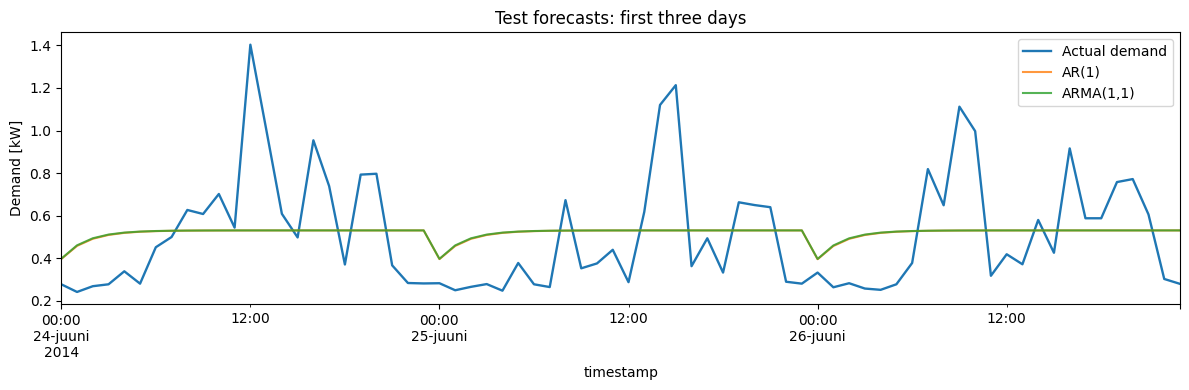

In [12]:
# I Compared models with the baselines from Task 7.
# Forecasted a full day (24 hours) at each midnight.
# updated the model after the day is finished.
# Calculated MAE and nRMSE with the fixed training mean.

# Seven 24-hour daily folds: forecast at midnight, update state only after the day.
# Store the predictions from each statistical model.
all_predictions = {}
for name, fitted in fits.items():
    current = fitted
    parts=[]
    for d in range(7):
        start=TEST_START+pd.Timedelta(days=d)
        actual=y.loc[start:start+pd.Timedelta(hours=23)]
        pred=current.get_forecast(steps=24).predicted_mean
        pred.index=actual.index
        parts.append(pred)
        # Updating the state uses the completed day's observations, not future observations.
        current=current.append(actual, refit=False)
    all_predictions[name]=pd.concat(parts)

# Recalculate baselines with EXACTLY the same 24-hour-at-midnight horizon.
# Do not use Demand.shift(1) across the test day: that would see future actuals.
base_parts={"Naive last value":[], "Seasonal lag-24":[],
            "Seasonal lag-168":[], "Moving average 24h":[]}
for d in range(7):
    start=TEST_START+pd.Timedelta(days=d)
    actual=y.loc[start:start+pd.Timedelta(hours=23)]
    history=y.loc[:start-pd.Timedelta(hours=1)]
    base_parts["Naive last value"].append(pd.Series(history.iloc[-1], index=actual.index))
    base_parts["Seasonal lag-24"].append(pd.Series(history.iloc[-24:].to_numpy(), index=actual.index))
    base_parts["Seasonal lag-168"].append(pd.Series(history.iloc[-168:-144].to_numpy(), index=actual.index))
    base_parts["Moving average 24h"].append(pd.Series(history.iloc[-24:].mean(), index=actual.index))
for name, parts in base_parts.items():
    all_predictions[name]=pd.concat(parts)

rows=[]
for name, pred in all_predictions.items():
    rows.append({"Model":name, "Evaluation":"24h daily walk-forward", **metrics(test, pred)})
# In-sample 1-step fitted values on training+validation; exclude early initialization.
for name, fit in fits.items():
    fitted_values=fit.fittedvalues.iloc[48:]
    truth=trainval.loc[fitted_values.index]
    rows.append({"Model":name, "Evaluation":"In-sample 1h fit", **metrics(truth, fitted_values)})
results=pd.DataFrame(rows)
display(results.round(3))
print("Best test model:", results.query('Evaluation == "24h daily walk-forward"').sort_values("nRMSE [%]").iloc[0]["Model"])
fig,ax=plt.subplots(figsize=(12,4))
test.iloc[:72].plot(ax=ax, label="Actual demand", lw=1.7)
for name in CANDIDATES:
    all_predictions[name].iloc[:72].plot(ax=ax, label=name, alpha=.8)
ax.set(title="Test forecasts: first three days",ylabel="Demand [kW]")
ax.legend();plt.tight_layout();plt.show()

**Answer 8.4**

I compared two statistical models, AR(1) and ARMA(1,1), with four baseline methods using 24-hour walk-forward forecasting over seven test days.

AR(1) achieved the best result, with MAE = 0.240 kW and nRMSE = 66.68%. ARMA(1,1) performed almost equally well, with nRMSE = 66.72%. Both models performed better than the four baselines.

I also compared in-sample and test errors. AR(1) had an in-sample nRMSE of 58.74%, compared with 66.68% on the test data. The test error was higher because the model had to forecast 24 hours without new demand observations.

The forecast plot shows that both models predict average demand reasonably well but fail to capture sudden consumption peaks. Overall, AR(1) is my preferred model because it is simpler and gives slightly better results.

**8.5. Which model performs better, and why?**

Best statistical model: AR(1) MAE: 0.2405 nRMSE: 66.68 %
Best baseline: Moving average 24h MAE: 0.2759 nRMSE: 74.07 %
nRMSE change relative to baseline (stat - baseline): -7.39 percentage points


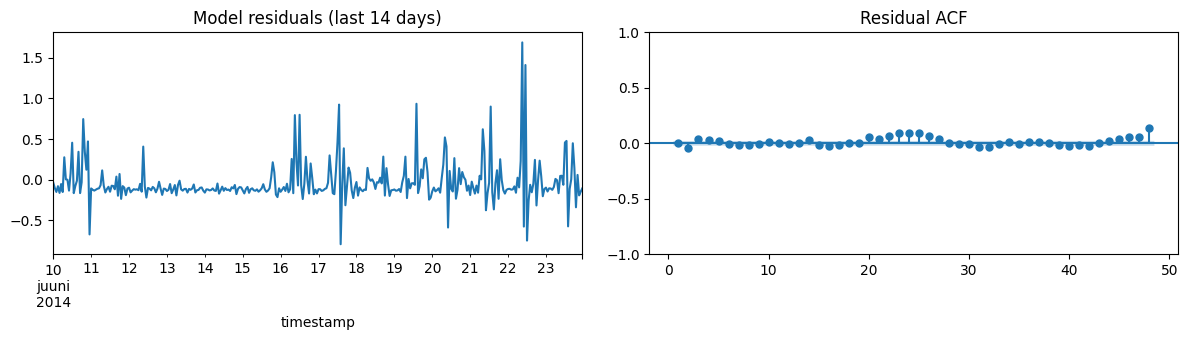

,lb_stat,lb_pvalue
24,276.9783,0.0


In [13]:
# Rank the statistical models by test error.
stat_rows=results[(results["Model"].isin(CANDIDATES)) &
                  (results["Evaluation"]=="24h daily walk-forward")].sort_values("nRMSE [%]")
baseline_rows=results[(~results["Model"].isin(CANDIDATES)) &
                      (results["Evaluation"]=="24h daily walk-forward")].sort_values("nRMSE [%]")
best_stat=stat_rows.iloc[0]
best_base=baseline_rows.iloc[0]
print("Best statistical model:", best_stat["Model"],
      "MAE:", round(best_stat["MAE [kW]"],4),
      "nRMSE:", round(best_stat["nRMSE [%]"],2), "%")
print("Best baseline:", best_base["Model"],
      "MAE:", round(best_base["MAE [kW]"],4),
      "nRMSE:", round(best_base["nRMSE [%]"],2), "%")
print("nRMSE change relative to baseline (stat - baseline):",
      round(best_stat["nRMSE [%]"]-best_base["nRMSE [%]"],2), "percentage points")

# Residual check from Practical 11
best_fit=fits[best_stat["Model"]]
burn=max(24, int(best_fit.loglikelihood_burn))
residuals=best_fit.resid.iloc[burn:].dropna()
fig,axs=plt.subplots(1,2,figsize=(12,3.5))
residuals.iloc[-24*14:].plot(ax=axs[0],title="Model residuals (last 14 days)")
plot_acf(residuals, lags=48, ax=axs[1], zero=False)
axs[1].set_title("Residual ACF")
plt.tight_layout();plt.show()
display(acorr_ljungbox(residuals, lags=[24], return_df=True).round(4))

**Answer 8.5:**

The AR(1) model performs slightly better than ARMA(1,1), because it has lower test errors and is simpler.

However, the residual analysis shows that AR(1) does not capture all demand patterns. The residual ACF shows daily correlation, and the Ljung–Box test (p < 0.05) confirms that residuals are not independent.

Therefore, AR(1) is the preferred model, but it could be improved by adding daily seasonality.


**8.6. Add your single strongest exogenous feature from Task 6, the same feature you will use in Task 9, to one of your ARMA-family models, giving a SARIMAX-type specification yt = φ(yt−1, yt−2, . . . , f1,t−1, . . . , εt). Report the change in MAE and normalised RMSE under the same protocol.**




Comment: In Assignment 6, `demand_lag1` was ranked highest, but it is another lag of the target and is already represented by the AR part. The strongest non-target exogenous feature in the previous Pearson ranking was `hour` (about 0.28). It is known in advance for every forecast hour. We therefore use hour of day as the single exogenous feature. We choose the pure ARMA order using **pre-test AIC** from the training+validation fit; the test set is not used to choose that order.

SARIMAX (1, 0, 0) with hour; AIC 4430.91 converged True


,MAE [kW],nRMSE [%]
Model,,
AR(1) (no exog),0.240,66.676
AR(1) + hour,0.223,65.066


Change in MAE (exog minus pure): -0.0171 kW
Change in nRMSE (exog minus pure): -1.61 percentage points


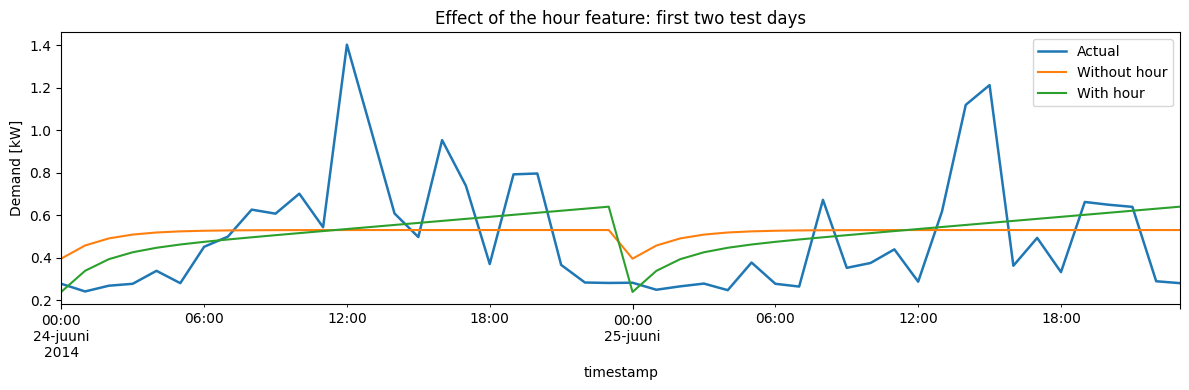

In [15]:
# Hour is known in advance for all 24 steps, so no future demand leakage.
# Created the hour feature for every timestamp.
exog_all=pd.DataFrame({"hour":y.index.hour.astype(float)},index=y.index)
exog_trainval=exog_all.loc[trainval.index]
chosen_name=min(fits, key=lambda name: fits[name].aic)  # choose using pre-test AIC, not test scores
chosen_order=CANDIDATES[chosen_name]
model_x=SARIMAX(trainval, exog=exog_trainval, order=chosen_order,
                trend="c", enforce_stationarity=True, enforce_invertibility=True)
fit_x=model_x.fit(disp=False,maxiter=120)
print("SARIMAX",chosen_order,"with hour; AIC",round(fit_x.aic,2),
      "converged",fit_x.mle_retvals.get("converged","unknown"))
current=fit_x; parts=[]
for d in range(7):
    start=TEST_START+pd.Timedelta(days=d)
    actual=y.loc[start:start+pd.Timedelta(hours=23)]
    future_exog=exog_all.loc[actual.index]
    pred=current.get_forecast(steps=24,exog=future_exog).predicted_mean
    pred.index=actual.index
    parts.append(pred)
    current=current.append(actual,exog=future_exog,refit=False)
pred_x=pd.concat(parts)
score_pure=metrics(test,all_predictions[chosen_name])
score_x=metrics(test,pred_x)
comparison=pd.DataFrame([
    {"Model":chosen_name+" (no exog)",**score_pure},
    {"Model":chosen_name+" + hour",**score_x}
]).set_index("Model")
display(comparison.round(3))
print("Change in MAE (exog minus pure):",round(score_x["MAE [kW]"]-score_pure["MAE [kW]"],4),"kW")
print("Change in nRMSE (exog minus pure):",round(score_x["nRMSE [%]"]-score_pure["nRMSE [%]"],2),"percentage points")
fig,ax=plt.subplots(figsize=(12,4))
test.iloc[:48].plot(ax=ax,label="Actual",lw=1.8)
all_predictions[chosen_name].iloc[:48].plot(ax=ax,label="Without hour")
pred_x.iloc[:48].plot(ax=ax,label="With hour")
ax.set(title="Effect of the hour feature: first two test days",ylabel="Demand [kW]")
ax.legend();plt.tight_layout();plt.show()

**Answer 8.6:** Adding the hour feature improves the AR(1) model. The nRMSE decreases from 66.68% to 65.07%.

The hour feature helps the model capture daily electricity demand patterns. However, the model still cannot predict sudden demand peaks.